In [ ]:
pip install pandas numpy matplotlib seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/retail_sales_eda_practice.csv')

In [ ]:
df.shape

(1000, 15)

In [ ]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Age,Gender,Product_Name,Category,Quantity,Unit_Price_INR,Discount_Percent,Sales_Revenue_INR,Profit_INR,Payment_Method,City,State
0,ORD00001,2024-07-04,CUST0174,46.0,Female,Perfume,Beauty,1,1242.15,15,1055.83,270.98,UPI,Kozhikode,Kerala
1,ORD00002,2024-06-15,CUST0160,27.0,Male,T-Shirt,Clothing,1,2891.61,10,2602.45,920.17,Net Banking,Bengaluru,Karnataka
2,ORD00003,2024-01-27,CUST0264,43.0,Male,Cooking Oil,Grocery,4,476.55,0,1906.20,419.36,Debit Card,Pune,Maharashtra
3,ORD00004,2024-02-13,CUST0276,18.0,Male,Moisturizer,Beauty,4,822.64,10,2961.50,1139.99,Debit Card,Vijayawada,Andhra Pradesh
4,ORD00005,2024-08-05,CUST0232,60.0,Male,USB Drive,Electronics,4,5344.56,0,21378.24,6512.53,Cash,Thiruvananthapuram,Kerala


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           1000 non-null   object 
 1   Order_Date         1000 non-null   object 
 2   Customer_ID        1000 non-null   object 
 3   Customer_Age       992 non-null    float64
 4   Gender             995 non-null    object 
 5   Product_Name       1000 non-null   object 
 6   Category           1000 non-null   object 
 7   Quantity           1000 non-null   int64  
 8   Unit_Price_INR     1000 non-null   float64
 9   Discount_Percent   1000 non-null   int64  
 10  Sales_Revenue_INR  1000 non-null   float64
 11  Profit_INR         1000 non-null   float64
 12  Payment_Method     996 non-null    object 
 13  City               1000 non-null   object 
 14  State              1000 non-null   object 
dtypes: float64(4), int64(2), object(9)
memory usage: 117.3+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Age,8
Gender,5
Product_Name,0
Category,0
Quantity,0
Unit_Price_INR,0
Discount_Percent,0


In [ ]:
missing_percentage=(df.isnull().sum()/len(df))*100
print(missing_percentage)

Order_ID             0.0
Order_Date           0.0
Customer_ID          0.0
Customer_Age         0.8
Gender               0.5
Product_Name         0.0
Category             0.0
Quantity             0.0
Unit_Price_INR       0.0
Discount_Percent     0.0
Sales_Revenue_INR    0.0
Profit_INR           0.0
Payment_Method       0.4
City                 0.0
State                0.0
dtype: float64


In [ ]:
df.dtypes

,0
Order_ID,object
Order_Date,object
Customer_ID,object
Customer_Age,float64
Gender,object
Product_Name,object
Category,object
Quantity,int64
Unit_Price_INR,float64
Discount_Percent,int64


In [ ]:
age_median = df['Customer_Age'].median()
df['Customer_Age'] = df['Customer_Age'].fillna(age_median)
print("Missing age values:", df['Customer_Age'].isnull().sum())
df['Customer_Age'] = df['Customer_Age'].astype(int)

Missing age values: 0


In [ ]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
print("Missing gender values:", df['Gender'].isnull().sum())

Missing gender values: 0


In [ ]:
df['Payment_Method']=df['Payment_Method'].fillna(df['Payment_Method'].mode()[0])
print("Missing payment method values:",df['Payment_Method'].isnull().sum())

Missing payment method values: 0


In [ ]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
print(df['Order_Date'].dtype)

datetime64[ns]


In [ ]:
df['Calculated_Revenue'] = (df['Quantity'] *df['Unit_Price_INR'] *(1 - df['Discount_Percent'] / 100))

In [ ]:
df.to_csv('/content/retail_sales_eda_practice.csv',index=False)

In [ ]:
from google.colab import files
files.download('/content/retail_sales_eda_practice.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Data validation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('/content/retail_sales_eda_practice (2).csv')

In [ ]:
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Values:")
print(df.duplicated().sum())

Dataset Shape: (1000, 16)

Data Types:
Order_ID               object
Order_Date             object
Customer_ID            object
Customer_Age            int64
Gender                 object
Product_Name           object
Category               object
Quantity                int64
Unit_Price_INR        float64
Discount_Percent        int64
Sales_Revenue_INR     float64
Profit_INR            float64
Payment_Method         object
City                   object
State                  object
Calculated_Revenue    float64
dtype: object

Missing Values:
Order_ID              0
Order_Date            0
Customer_ID           0
Customer_Age          0
Gender                0
Product_Name          0
Category              0
Quantity              0
Unit_Price_INR        0
Discount_Percent      0
Sales_Revenue_INR     0
Profit_INR            0
Payment_Method        0
City                  0
State                 0
Calculated_Revenue    0
dtype: int64

Duplicate Values:
0


In [ ]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Customer_Age'] = df['Customer_Age'].astype(int)

In [ ]:

numeric_df = df.select_dtypes(include='number')
print("MEAN")
print(numeric_df.mean())
print("\nMEDIAN")
print(numeric_df.median())
print("\nMODE")
print(numeric_df.mode().iloc[0])
print("\nSTANDARD DEVIATION")
print(numeric_df.std())
print("\nDESCRIPTIVE STATISTICS")
print(numeric_df.describe())

MEAN
Customer_Age            41.265000
Quantity                 3.003000
Unit_Price_INR        1896.993520
Discount_Percent         6.580000
Sales_Revenue_INR     5373.979560
Profit_INR            1699.043690
Calculated_Revenue    5373.979388
dtype: float64

MEDIAN
Customer_Age            41.000
Quantity                 3.000
Unit_Price_INR        1362.385
Discount_Percent         5.000
Sales_Revenue_INR     3410.720
Profit_INR            1079.610
Calculated_Revenue    3410.720
dtype: float64

MODE
Customer_Age          43.00
Quantity               3.00
Unit_Price_INR        63.86
Discount_Percent       0.00
Sales_Revenue_INR     77.32
Profit_INR            18.61
Calculated_Revenue    77.32
Name: 0, dtype: float64

STANDARD DEVIATION
Customer_Age            13.817659
Quantity                 1.397478
Unit_Price_INR        1549.309910
Discount_Percent         6.236385
Sales_Revenue_INR     5499.376317
Profit_INR            1789.771844
Calculated_Revenue    5499.376299
dtype: float64

DE

#Month Column

In [ ]:
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.month_name()
df['Quarter'] = df['Order_Date'].dt.quarter

#Monthly Revenue

In [ ]:
monthly_sales = df.groupby('Month_Name')['Sales_Revenue_INR'].sum()
print(monthly_sales)

Month_Name
April        372494.11
August       424456.99
December     380102.24
February     619352.38
January      473047.20
July         461354.55
June         502229.14
March        413232.69
May          461019.75
November     406164.87
October      466226.93
September    394298.71
Name: Sales_Revenue_INR, dtype: float64


#Monthly Revenue

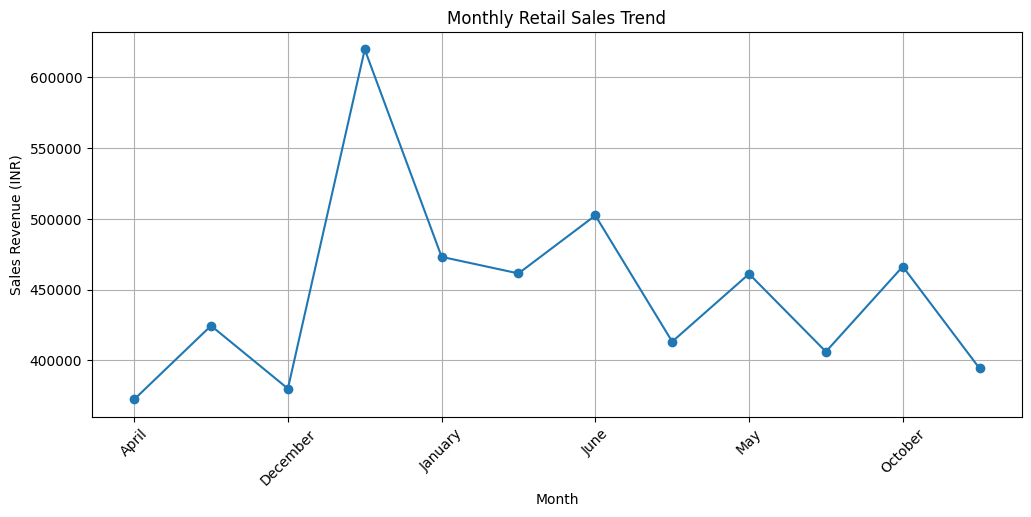

In [ ]:
monthly_sales.plot(kind='line',marker='o',figsize=(12,5))
plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Revenue (INR)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

#Age & Gender analyse

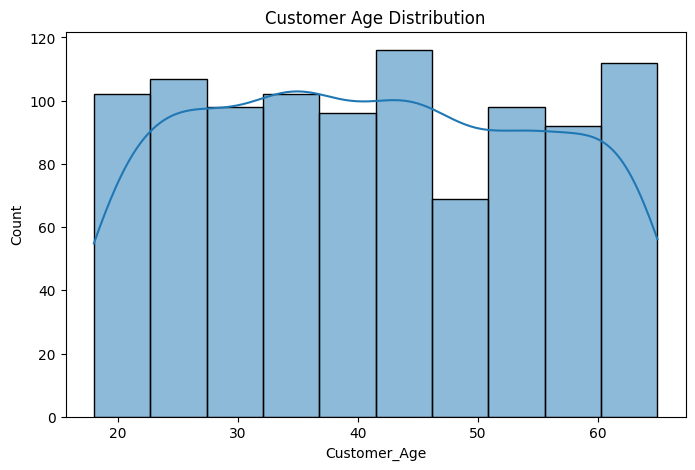

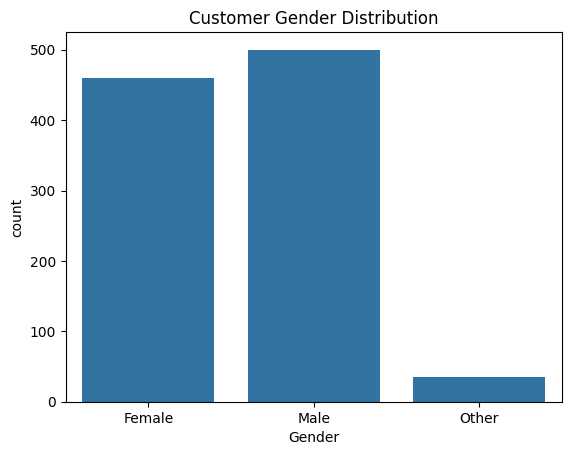

In [5]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x='Customer_Age',bins=10,kde=True)
plt.title('Customer Age Distribution')
plt.show()
sns.countplot(data=df,x='Gender')
plt.title('Customer Gender Distribution')
plt.show()

# Product Analysis

In [6]:
top_products = df.groupby('Product_Name')['Quantity'].sum().sort_values(ascending=False).head(10)
print(top_products)

Product_Name
T-Shirt             193
Headphones          173
Breakfast Cereal    148
Smart Watch         147
USB Drive           136
Cookware Set        135
Keyboard            131
Wireless Mouse      128
Dress               125
Jeans               123
Name: Quantity, dtype: int64


#TOP 10Selling Products

In [7]:
top_products = df.groupby('Product_Name')['Quantity'].sum().sort_values(ascending=False).head(10)
print(top_products)

Product_Name
T-Shirt             193
Headphones          173
Breakfast Cereal    148
Smart Watch         147
USB Drive           136
Cookware Set        135
Keyboard            131
Wireless Mouse      128
Dress               125
Jeans               123
Name: Quantity, dtype: int64


#Bar chart

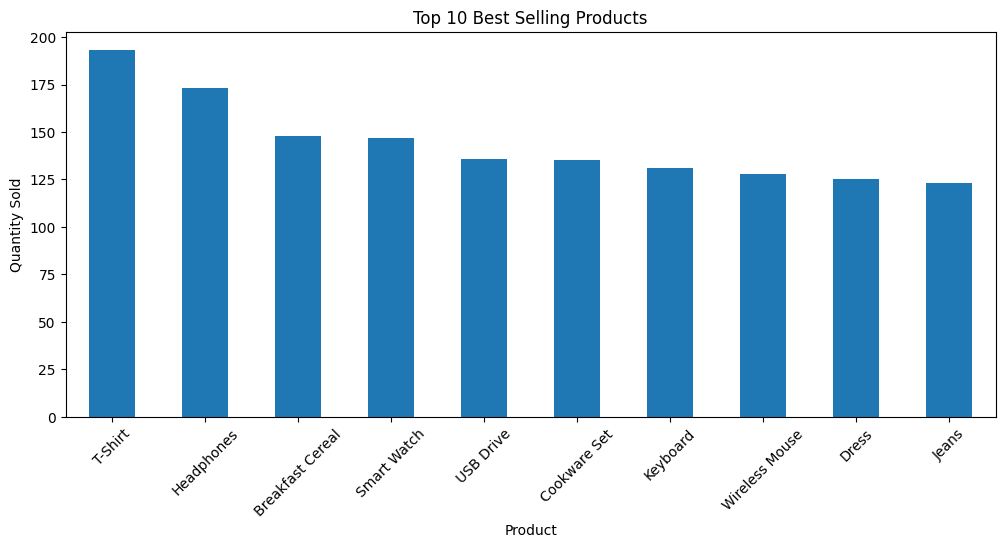

In [8]:
top_products.plot(kind='bar',figsize=(12,5))
plt.title('Top 10 Best Selling Products')
plt.xlabel('Product')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45)
plt.show()

#Category Wise Revenue

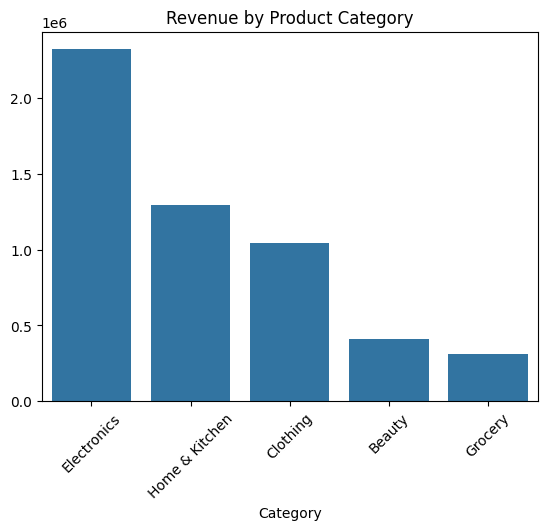

In [9]:
category_sales = df.groupby('Category')['Sales_Revenue_INR'].sum().sort_values(ascending=False)
sns.barplot(x=category_sales.index,y=category_sales.values)
plt.title('Revenue by Product Category')
plt.xticks(rotation=45)
plt.show()

#Correlation heatmap To understand relationships between numerical variables.

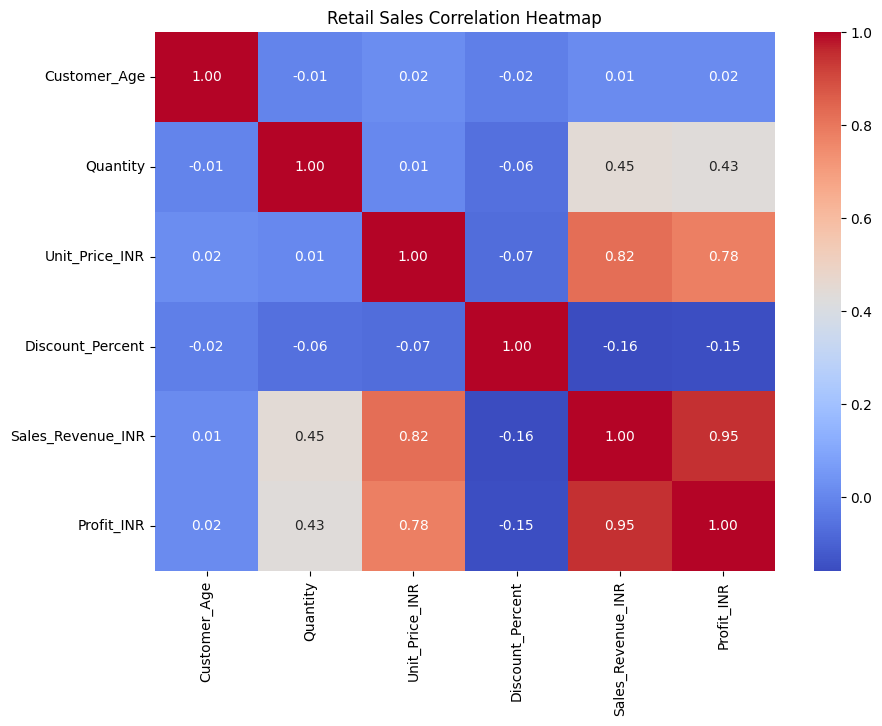

In [11]:
plt.figure(figsize=(10,7))
correlation = df.select_dtypes(
    include='number').corr()
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Retail Sales Correlation Heatmap')
plt.show()